In [3]:
#라이브러리 불러오기
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 예전 pandas pickle 호환 처리
import sys
import pickle
import pandas.core.indexes as pd_indexes
import pandas.core.indexes.base as pd_indexes_base
import pandas.core.indexes.range as pd_indexes_range

# 오래된 pandas pickle 호환 처리
sys.modules["pandas.indexes"] = pd_indexes
sys.modules["pandas.indexes.base"] = pd_indexes_base
sys.modules["pandas.indexes.range"] = pd_indexes_range

In [4]:
#데이터 불러오기
file_path = r"C:\Users\rosa_\OneDrive\바탕 화면\4학년 1학기\빅데이터분석\project\data\LSWMD.pkl"

# pd.read_pickle() 말고 pickle.load()로 읽기
with open(file_path, "rb") as f:
    df = pickle.load(f, encoding="latin1")

df.head()

,waferMap,dieSize,lotName,waferIndex,trianTestLabel,failureType
0,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,1.0,[[Training]],[[none]]
1,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,2.0,[[Training]],[[none]]
2,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,3.0,[[Training]],[[none]]
3,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,4.0,[[Training]],[[none]]
4,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,5.0,[[Training]],[[none]]


In [7]:
import sys
!{sys.executable} -m pip install openpyxl

  Using cached openpyxl-3.1.5-py2.py3-none-any.whl.metadata (2.5 kB)
  Using cached et_xmlfile-2.0.0-py3-none-any.whl.metadata (2.7 kB)
Using cached openpyxl-3.1.5-py2.py3-none-any.whl (250 kB)
Using cached et_xmlfile-2.0.0-py3-none-any.whl (18 kB)

   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------

In [8]:
#라벨 정제 전의 원본 데이터 상태를 요약해서 저장
import io

save_path = r"C:\Users\rosa_\OneDrive\바탕 화면\4학년 1학기\빅데이터분석\project\data\wafer_dataset_summary.xlsx"

# 1. 데이터 크기
shape_df = pd.DataFrame({
    "항목": ["행 개수", "열 개수"],
    "값": [df.shape[0], df.shape[1]]
})

# 2. 컬럼 목록
columns_df = pd.DataFrame({
    "컬럼명": df.columns
})

# 3. 컬럼별 타입 및 결측치
dtypes_df = pd.DataFrame({
    "컬럼명": df.columns,
    "데이터타입": df.dtypes.astype(str).values,
    "결측치 수": df.isna().sum().values
})

# 4. df.info() 결과 저장
buffer = io.StringIO()
df.info(buf=buffer)
info_text = buffer.getvalue().splitlines()

info_df = pd.DataFrame({
    "df.info() 출력 결과": info_text
})

# 5. 앞 5개 샘플 저장, waferMap은 너무 길어서 제외
head_df = df.head()[["dieSize", "lotName", "waferIndex", "trianTestLabel", "failureType"]].copy()

# 배열 형태 컬럼은 문자열로 변환
head_df["trianTestLabel"] = head_df["trianTestLabel"].astype(str)
head_df["failureType"] = head_df["failureType"].astype(str)

# 엑셀 저장
with pd.ExcelWriter(save_path, engine="openpyxl") as writer:
    shape_df.to_excel(writer, sheet_name="데이터_크기", index=False)
    columns_df.to_excel(writer, sheet_name="컬럼_목록", index=False)
    dtypes_df.to_excel(writer, sheet_name="컬럼_정보", index=False)
    info_df.to_excel(writer, sheet_name="df_info", index=False)
    head_df.to_excel(writer, sheet_name="앞5개_샘플", index=False)

print("엑셀 저장 완료:", save_path)

엑셀 저장 완료: C:\Users\rosa_\OneDrive\바탕 화면\4학년 1학기\빅데이터분석\project\data\wafer_dataset_summary.xlsx


In [9]:
# 라벨 정리: failureType과 trianTestLabel이 배열 형태라서 문자열로 변환

def clean_label(x):
    arr = np.array(x).flatten()
    
    if len(arr) == 0:
        return "Unknown"
    
    return str(arr[0])

df["failureType_clean"] = df["failureType"].apply(clean_label)
df["trainTestLabel_clean"] = df["trianTestLabel"].apply(clean_label)

df[["failureType", "failureType_clean", "trianTestLabel", "trainTestLabel_clean"]].head()

,failureType,failureType_clean,trianTestLabel,trainTestLabel_clean
0,[[none]],none,[[Training]],Training
1,[[none]],none,[[Training]],Training
2,[[none]],none,[[Training]],Training
3,[[none]],none,[[Training]],Training
4,[[none]],none,[[Training]],Training


In [11]:
# 정리된 라벨 분포 확인
from IPython.display import display

print("failureType_clean 분포")
display(df["failureType_clean"].value_counts())
#train/test 라벨
print("trainTestLabel_clean 분포")
display(df["trainTestLabel_clean"].value_counts())

failureType_clean 분포


failureType_clean
Unknown      638507
none         147431
Edge-Ring      9680
Edge-Loc       5189
Center         4294
Loc            3593
Scratch        1193
Random          866
Donut           555
Near-full       149
Name: count, dtype: int64

trainTestLabel_clean 분포


trainTestLabel_clean
Unknown     638507
Test        118595
Training     54355
Name: count, dtype: int64

In [12]:
# 라벨이 있는 데이터만 추출
df_labeled = df[df["failureType_clean"] != "Unknown"].copy()

print(df_labeled.shape)
display(df_labeled["failureType_clean"].value_counts())

(172950, 8)


failureType_clean
none         147431
Edge-Ring      9680
Edge-Loc       5189
Center         4294
Loc            3593
Scratch        1193
Random          866
Donut           555
Near-full       149
Name: count, dtype: int64

In [13]:
# 분석용 데이터: none 포함
df_analysis = df_labeled.copy()

# 예측용 데이터: none 제외
df_predict = df_labeled[df_labeled["failureType_clean"] != "none"].copy()

print("분석용 데이터:", df_analysis.shape)
print("예측용 데이터:", df_predict.shape)

display(df_analysis["failureType_clean"].value_counts())
display(df_predict["failureType_clean"].value_counts())

분석용 데이터: (172950, 8)
예측용 데이터: (25519, 8)


failureType_clean
none         147431
Edge-Ring      9680
Edge-Loc       5189
Center         4294
Loc            3593
Scratch        1193
Random          866
Donut           555
Near-full       149
Name: count, dtype: int64

failureType_clean
Edge-Ring    9680
Edge-Loc     5189
Center       4294
Loc          3593
Scratch      1193
Random        866
Donut         555
Near-full     149
Name: count, dtype: int64

In [ ]:
#정제 결과 데이터 저장
save_path = r"C:\Users\rosa_\OneDrive\바탕 화면\4학년 1학기\빅데이터분석\project\data\wafer_labeled_clean.xlsx"

df_labeled_excel = df_labeled[
    [
        "dieSize",
        "lotName",
        "waferIndex",
        "trainTestLabel_clean",
        "failureType_clean"
    ]
].copy()

df_labeled_excel.to_excel(save_path, index=False)

print("라벨 정제 데이터 저장 완료:", save_path)

라벨 정제 데이터 저장 완료: C:\Users\rosa_\OneDrive\바탕 화면\4학년 1학기\빅데이터분석\project\data\wafer_labeled_clean.xlsx


In [15]:
# 분석용 데이터: none 포함
# 목적: 전체 라벨 데이터 분포, 정상/무패턴과 불량 패턴 비율 분석
df_analysis = df_labeled.copy()

# 예측용 데이터: none 제외
# 목적: 실제 불량 패턴 유형 예측
df_predict = df_labeled[df_labeled["failureType_clean"] != "none"].copy()

print("분석용 데이터 크기:", df_analysis.shape)
print("예측용 데이터 크기:", df_predict.shape)

print("\n[분석용 데이터 라벨 분포]")
display(df_analysis["failureType_clean"].value_counts())

print("\n[예측용 데이터 라벨 분포]")
display(df_predict["failureType_clean"].value_counts())

분석용 데이터 크기: (172950, 8)
예측용 데이터 크기: (25519, 8)

[분석용 데이터 라벨 분포]


failureType_clean
none         147431
Edge-Ring      9680
Edge-Loc       5189
Center         4294
Loc            3593
Scratch        1193
Random          866
Donut           555
Near-full       149
Name: count, dtype: int64


[예측용 데이터 라벨 분포]


failureType_clean
Edge-Ring    9680
Edge-Loc     5189
Center       4294
Loc          3593
Scratch      1193
Random        866
Donut         555
Near-full     149
Name: count, dtype: int64

In [16]:
save_path = r"C:\Users\rosa_\OneDrive\바탕 화면\4학년 1학기\빅데이터분석\project\data\wafer_predict_data.xlsx"

df_predict_excel = df_predict[
    [
        "dieSize",
        "lotName",
        "waferIndex",
        "trainTestLabel_clean",
        "failureType_clean"
    ]
].copy()

df_predict_excel.to_excel(save_path, index=False)

print("예측용 데이터 저장 완료:", save_path)

예측용 데이터 저장 완료: C:\Users\rosa_\OneDrive\바탕 화면\4학년 1학기\빅데이터분석\project\data\wafer_predict_data.xlsx


In [17]:
# 주요 6개 클래스만 선택
target_classes = ["Center", "Edge-Loc", "Edge-Ring", "Loc", "Random", "Scratch"]

df_model = df_predict[df_predict["failureType_clean"].isin(target_classes)].copy()

print("모델용 데이터 크기:", df_model.shape)
display(df_model["failureType_clean"].value_counts())

모델용 데이터 크기: (24815, 8)


failureType_clean
Edge-Ring    9680
Edge-Loc     5189
Center       4294
Loc          3593
Scratch      1193
Random        866
Name: count, dtype: int64

In [18]:
save_path = r"C:\Users\rosa_\OneDrive\바탕 화면\4학년 1학기\빅데이터분석\project\data\wafer_model_6class.xlsx"

df_model_excel = df_model[
    [
        "dieSize",
        "lotName",
        "waferIndex",
        "trainTestLabel_clean",
        "failureType_clean"
    ]
].copy()

df_model_excel.to_excel(save_path, index=False)

print("6개 클래스 모델용 데이터 저장 완료:", save_path)

6개 클래스 모델용 데이터 저장 완료: C:\Users\rosa_\OneDrive\바탕 화면\4학년 1학기\빅데이터분석\project\data\wafer_model_6class.xlsx


In [19]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

fig_dir = r"C:\Users\rosa_\OneDrive\바탕 화면\4학년 1학기\빅데이터분석\project\data\figures"
os.makedirs(fig_dir, exist_ok=True)

print("시각화 저장 폴더:", fig_dir)

시각화 저장 폴더: C:\Users\rosa_\OneDrive\바탕 화면\4학년 1학기\빅데이터분석\project\data\figures


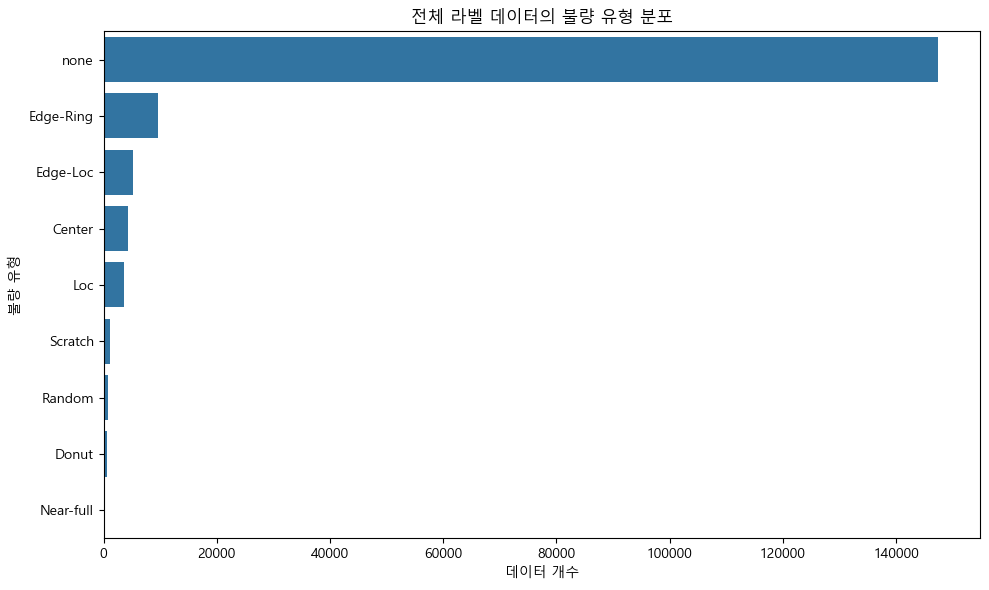

failureType_clean
none         147431
Edge-Ring      9680
Edge-Loc       5189
Center         4294
Loc            3593
Scratch        1193
Random          866
Donut           555
Near-full       149
Name: count, dtype: int64

In [20]:
class_counts = df_analysis["failureType_clean"].value_counts()

plt.figure(figsize=(10, 6))
sns.barplot(x=class_counts.values, y=class_counts.index)

plt.title("전체 라벨 데이터의 불량 유형 분포")
plt.xlabel("데이터 개수")
plt.ylabel("불량 유형")

plt.tight_layout()
plt.savefig(os.path.join(fig_dir, "01_전체_라벨_클래스_분포.png"), dpi=300)
plt.show()

class_counts

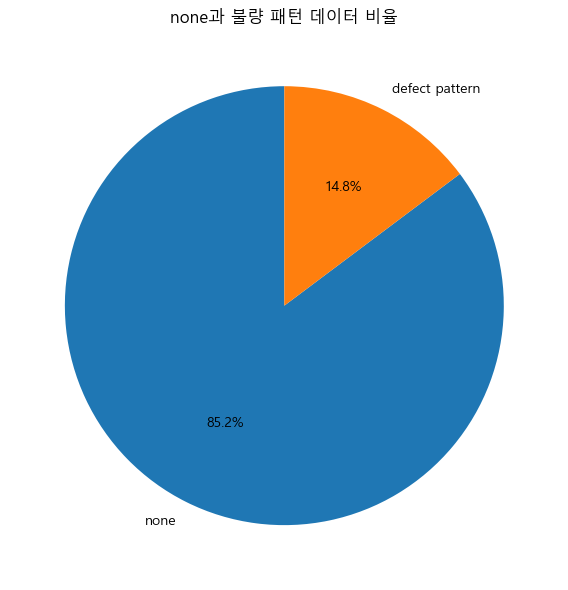

pattern_group
none              147431
defect pattern     25519
Name: count, dtype: int64

In [21]:
df_analysis["pattern_group"] = df_analysis["failureType_clean"].apply(
    lambda x: "none" if x == "none" else "defect pattern"
)

group_counts = df_analysis["pattern_group"].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(
    group_counts.values,
    labels=group_counts.index,
    autopct="%.1f%%",
    startangle=90
)

plt.title("none과 불량 패턴 데이터 비율")
plt.tight_layout()
plt.savefig(os.path.join(fig_dir, "02_none_불량패턴_비율.png"), dpi=300)
plt.show()

group_counts

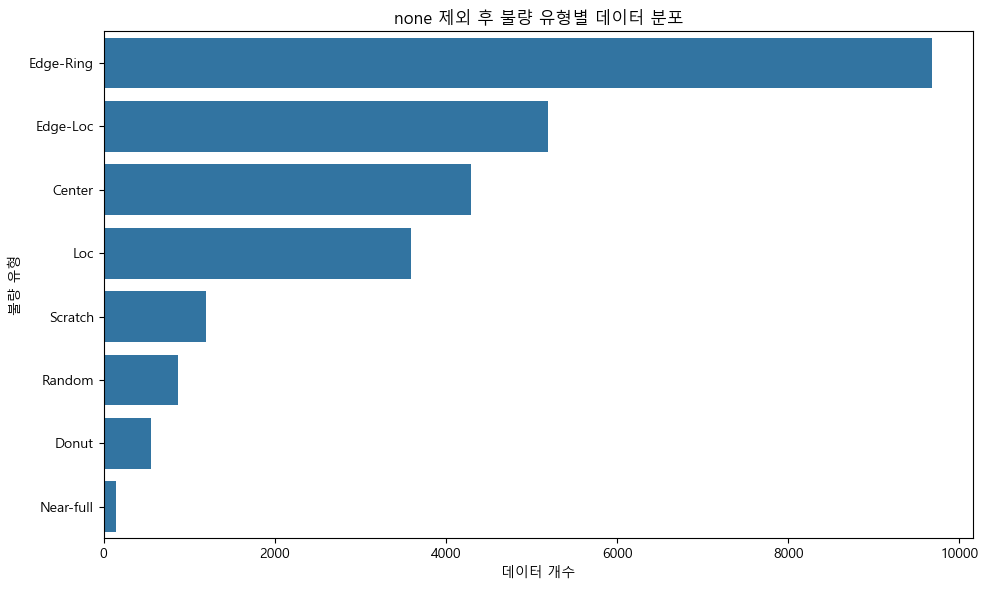

failureType_clean
Edge-Ring    9680
Edge-Loc     5189
Center       4294
Loc          3593
Scratch      1193
Random        866
Donut         555
Near-full     149
Name: count, dtype: int64

In [22]:
predict_counts = df_predict["failureType_clean"].value_counts()

plt.figure(figsize=(10, 6))
sns.barplot(x=predict_counts.values, y=predict_counts.index)

plt.title("none 제외 후 불량 유형별 데이터 분포")
plt.xlabel("데이터 개수")
plt.ylabel("불량 유형")

plt.tight_layout()
plt.savefig(os.path.join(fig_dir, "03_none제외_불량유형_분포.png"), dpi=300)
plt.show()

predict_counts

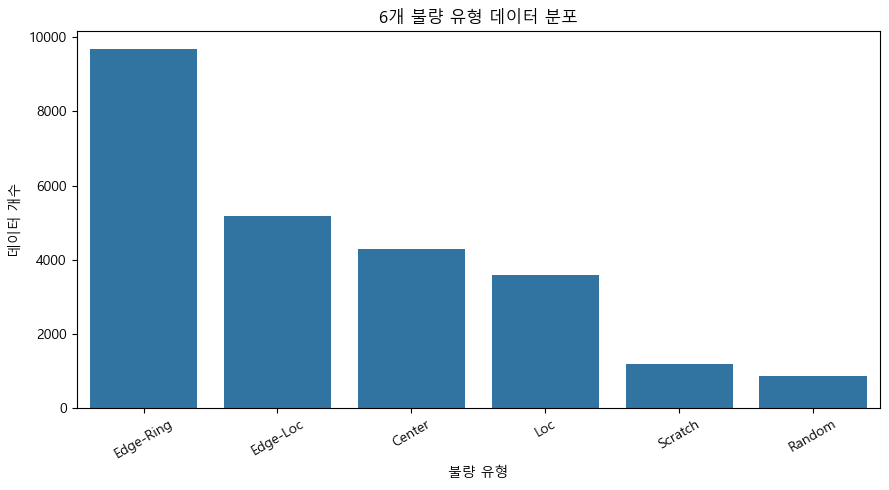

failureType_clean
Edge-Ring    9680
Edge-Loc     5189
Center       4294
Loc          3593
Scratch      1193
Random        866
Name: count, dtype: int64

In [24]:
model_counts = df_model["failureType_clean"].value_counts()

plt.figure(figsize=(9, 5))
sns.barplot(x=model_counts.index, y=model_counts.values)

plt.title("6개 불량 유형 데이터 분포")
plt.xlabel("불량 유형")
plt.ylabel("데이터 개수")
plt.xticks(rotation=30)

plt.tight_layout()
plt.savefig(os.path.join(fig_dir, "04_모델용_6개_클래스_분포.png"), dpi=300)
plt.show()

model_counts

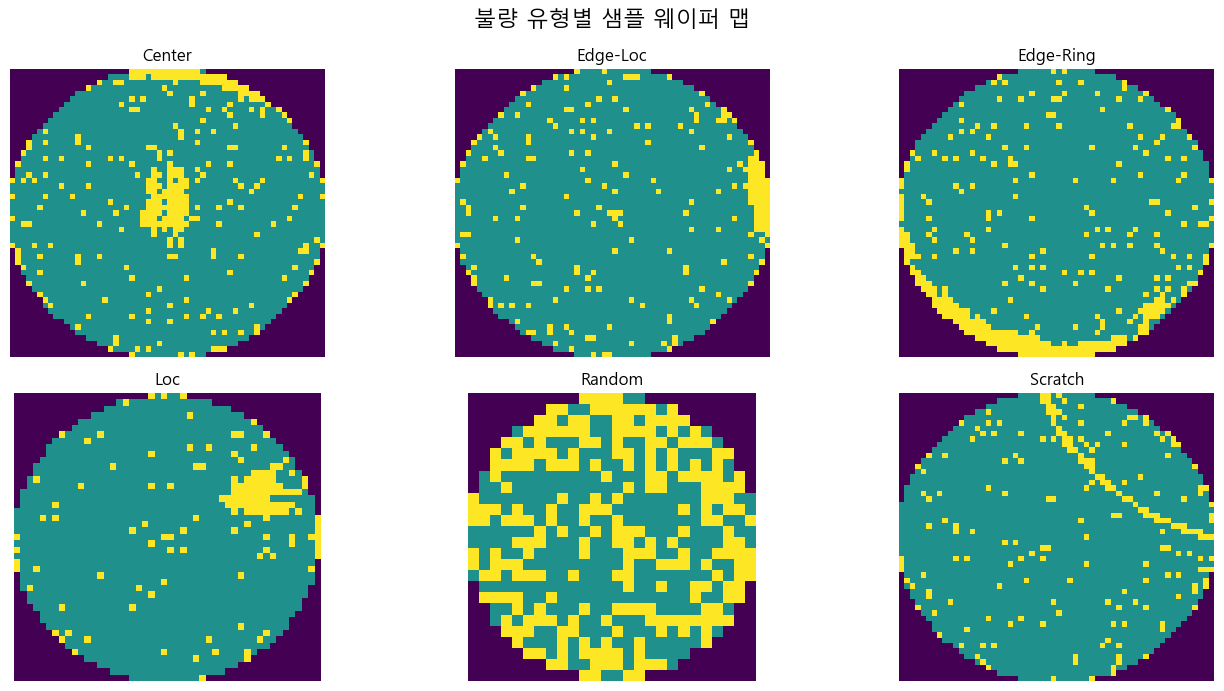

In [25]:
classes = ["Center", "Edge-Loc", "Edge-Ring", "Loc", "Random", "Scratch"]

plt.figure(figsize=(14, 7))

for i, cls in enumerate(classes):
    sample = df_model[df_model["failureType_clean"] == cls].iloc[0]
    wafer_map = np.array(sample["waferMap"])
    
    plt.subplot(2, 3, i + 1)
    plt.imshow(wafer_map)
    plt.title(cls)
    plt.axis("off")

plt.suptitle("불량 유형별 샘플 웨이퍼 맵", fontsize=16)
plt.tight_layout()
plt.savefig(os.path.join(fig_dir, "05_불량유형별_샘플_웨이퍼맵.png"), dpi=300)
plt.show()

In [26]:
# 웨이퍼 맵에서 수치형 파생 변수 추출

def extract_wafer_features(wafer_map):
    wm = np.array(wafer_map)
    
    height, width = wm.shape
    
    # 0: 배경, 1: 정상 die, 2: 불량 die
    die_mask = wm > 0
    defect_mask = wm == 2
    normal_mask = wm == 1
    
    total_die = die_mask.sum()
    normal_die_count = normal_mask.sum()
    defect_die_count = defect_mask.sum()
    
    defect_ratio = defect_die_count / total_die if total_die > 0 else 0
    
    # 좌표 생성
    y_idx, x_idx = np.indices(wm.shape)
    
    # 0~1 범위의 좌표로 변환
    x_norm = x_idx / (width - 1) if width > 1 else x_idx
    y_norm = y_idx / (height - 1) if height > 1 else y_idx
    
    # 불량 die 중심 좌표
    if defect_die_count > 0:
        defect_center_x = x_norm[defect_mask].mean()
        defect_center_y = y_norm[defect_mask].mean()
        defect_spread_x = x_norm[defect_mask].std()
        defect_spread_y = y_norm[defect_mask].std()
    else:
        defect_center_x = 0
        defect_center_y = 0
        defect_spread_x = 0
        defect_spread_y = 0
    
    # 중심/가장자리 영역 구분
    cx, cy = 0.5, 0.5
    distance = np.sqrt((x_norm - cx) ** 2 + (y_norm - cy) ** 2)
    
    center_zone = distance <= 0.25
    edge_zone = distance >= 0.40
    
    center_die_count = (die_mask & center_zone).sum()
    edge_die_count = (die_mask & edge_zone).sum()
    
    center_defect_count = (defect_mask & center_zone).sum()
    edge_defect_count = (defect_mask & edge_zone).sum()
    
    center_defect_ratio = center_defect_count / center_die_count if center_die_count > 0 else 0
    edge_defect_ratio = edge_defect_count / edge_die_count if edge_die_count > 0 else 0
    
    return pd.Series({
        "wafer_height": height,
        "wafer_width": width,
        "total_die": total_die,
        "normal_die_count": normal_die_count,
        "defect_die_count": defect_die_count,
        "defect_ratio": defect_ratio,
        "defect_center_x": defect_center_x,
        "defect_center_y": defect_center_y,
        "defect_spread_x": defect_spread_x,
        "defect_spread_y": defect_spread_y,
        "center_defect_ratio": center_defect_ratio,
        "edge_defect_ratio": edge_defect_ratio
    })

In [27]:
# df_model에 파생 변수 생성
feature_df = df_model["waferMap"].apply(extract_wafer_features)

df_features = pd.concat(
    [
        df_model[
            [
                "dieSize",
                "lotName",
                "waferIndex",
                "trainTestLabel_clean",
                "failureType_clean"
            ]
        ].reset_index(drop=True),
        feature_df.reset_index(drop=True)
    ],
    axis=1
)

df_features.head()

,dieSize,lotName,waferIndex,trainTestLabel_clean,failureType_clean,wafer_height,wafer_width,total_die,normal_die_count,defect_die_count,defect_ratio,defect_center_x,defect_center_y,defect_spread_x,defect_spread_y,center_defect_ratio,edge_defect_ratio
0,1683.0,lot1,20.0,Training,Loc,45.0,48.0,1683.0,1537.0,146.0,0.086750,0.659429,0.427148,0.266403,0.212468,0.047030,0.102041
1,2460.0,lot2,12.0,Training,Edge-Loc,53.0,58.0,2460.0,2241.0,219.0,0.089024,0.580790,0.473042,0.322755,0.261882,0.046875,0.147423
2,2460.0,lot2,13.0,Training,Edge-Loc,53.0,58.0,2460.0,2221.0,239.0,0.097154,0.579094,0.467895,0.319966,0.249727,0.062500,0.147423
3,2460.0,lot2,14.0,Training,Edge-Loc,53.0,58.0,2460.0,2190.0,270.0,0.109756,0.614425,0.457977,0.318585,0.245329,0.064236,0.183505
4,2460.0,lot2,15.0,Training,Edge-Loc,53.0,58.0,2460.0,2186.0,274.0,0.111382,0.614035,0.414865,0.300149,0.273358,0.045139,0.201031


In [28]:
print(df_features.shape)
display(df_features.head())
display(df_features.describe())

(24815, 17)


,dieSize,lotName,waferIndex,trainTestLabel_clean,failureType_clean,wafer_height,wafer_width,total_die,normal_die_count,defect_die_count,defect_ratio,defect_center_x,defect_center_y,defect_spread_x,defect_spread_y,center_defect_ratio,edge_defect_ratio
0,1683.0,lot1,20.0,Training,Loc,45.0,48.0,1683.0,1537.0,146.0,0.086750,0.659429,0.427148,0.266403,0.212468,0.047030,0.102041
1,2460.0,lot2,12.0,Training,Edge-Loc,53.0,58.0,2460.0,2241.0,219.0,0.089024,0.580790,0.473042,0.322755,0.261882,0.046875,0.147423
2,2460.0,lot2,13.0,Training,Edge-Loc,53.0,58.0,2460.0,2221.0,239.0,0.097154,0.579094,0.467895,0.319966,0.249727,0.062500,0.147423
3,2460.0,lot2,14.0,Training,Edge-Loc,53.0,58.0,2460.0,2190.0,270.0,0.109756,0.614425,0.457977,0.318585,0.245329,0.064236,0.183505
4,2460.0,lot2,15.0,Training,Edge-Loc,53.0,58.0,2460.0,2186.0,274.0,0.111382,0.614035,0.414865,0.300149,0.273358,0.045139,0.201031


,dieSize,waferIndex,wafer_height,wafer_width,total_die,normal_die_count,defect_die_count,defect_ratio,defect_center_x,defect_center_y,defect_spread_x,defect_spread_y,center_defect_ratio,edge_defect_ratio
count,24815.000000,24815.000000,24815.000000,24815.000000,24815.000000,24815.000000,24815.000000,24815.000000,24815.000000,24815.000000,24815.000000,24815.000000,24815.000000,24815.000000
mean,1754.074511,13.058674,43.262180,43.478622,1754.074511,1520.413500,233.661011,0.180809,0.501572,0.505885,0.282577,0.282418,0.157845,0.262306
std,2126.254009,7.233892,18.474269,21.677602,2126.254009,2033.565656,178.471048,0.108338,0.055868,0.057965,0.038560,0.038428,0.176664,0.121962
min,439.000000,1.000000,22.000000,18.000000,439.000000,131.000000,5.000000,0.005150,0.102679,0.116177,0.016496,0.015528,0.000000,0.000000
25%,741.000000,7.000000,31.000000,30.000000,741.000000,553.000000,127.000000,0.114290,0.479758,0.483550,0.256332,0.256545,0.043651,0.181034
50%,1091.000000,13.000000,39.000000,37.000000,1091.000000,897.000000,191.000000,0.155213,0.501078,0.504882,0.284419,0.284432,0.083333,0.261364
75%,2085.000000,19.000000,53.000000,52.000000,2085.000000,1780.000000,280.000000,0.225116,0.523859,0.526482,0.315474,0.315593,0.200708,0.332162
max,22372.000000,25.000000,212.000000,204.000000,22372.000000,20588.000000,5494.000000,0.770533,0.928571,0.864035,0.406891,0.396725,1.000000,0.971963


In [29]:
save_path = r"C:\Users\rosa_\OneDrive\바탕 화면\4학년 1학기\빅데이터분석\project\data\wafer_features_6class.xlsx"

df_features.to_excel(save_path, index=False)

print("파생 변수 데이터 저장 완료:", save_path)

파생 변수 데이터 저장 완료: C:\Users\rosa_\OneDrive\바탕 화면\4학년 1학기\빅데이터분석\project\data\wafer_features_6class.xlsx


In [30]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

fig_dir = r"C:\Users\rosa_\OneDrive\바탕 화면\4학년 1학기\빅데이터분석\project\data\figures"
os.makedirs(fig_dir, exist_ok=True)

print("시각화 저장 폴더:", fig_dir)

시각화 저장 폴더: C:\Users\rosa_\OneDrive\바탕 화면\4학년 1학기\빅데이터분석\project\data\figures


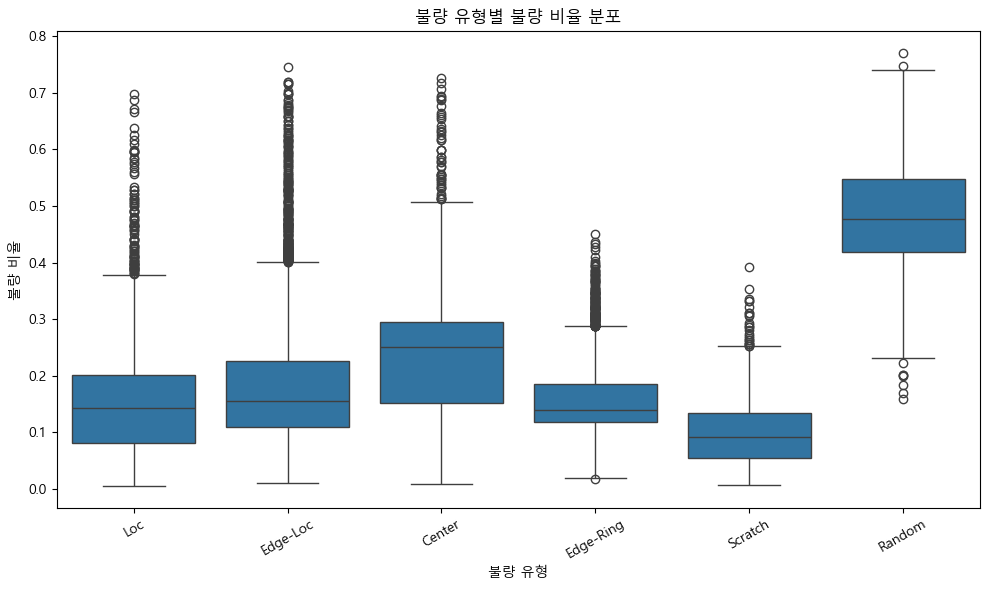

In [31]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_features,
    x="failureType_clean",
    y="defect_ratio"
)

plt.title("불량 유형별 불량 비율 분포")
plt.xlabel("불량 유형")
plt.ylabel("불량 비율")
plt.xticks(rotation=30)

plt.tight_layout()
plt.savefig(os.path.join(fig_dir, "06_불량유형별_defect_ratio_boxplot.png"), dpi=300)
plt.show()

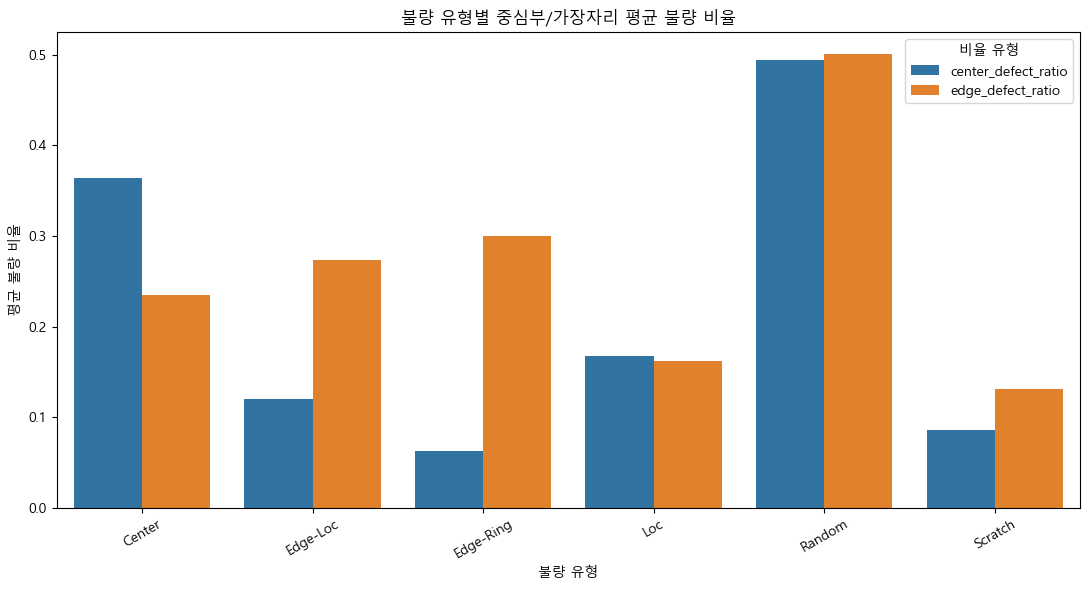

,failureType_clean,center_defect_ratio,edge_defect_ratio
0,Center,0.363522,0.235164
1,Edge-Loc,0.119779,0.273603
2,Edge-Ring,0.062243,0.300182
3,Loc,0.167150,0.162450
4,Random,0.494826,0.500376
5,Scratch,0.086179,0.131458


In [32]:
ratio_mean = df_features.groupby("failureType_clean")[
    ["center_defect_ratio", "edge_defect_ratio"]
].mean().reset_index()

ratio_melt = ratio_mean.melt(
    id_vars="failureType_clean",
    value_vars=["center_defect_ratio", "edge_defect_ratio"],
    var_name="ratio_type",
    value_name="ratio"
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=ratio_melt,
    x="failureType_clean",
    y="ratio",
    hue="ratio_type"
)

plt.title("불량 유형별 중심부/가장자리 평균 불량 비율")
plt.xlabel("불량 유형")
plt.ylabel("평균 불량 비율")
plt.xticks(rotation=30)
plt.legend(title="비율 유형")

plt.tight_layout()
plt.savefig(os.path.join(fig_dir, "07_중심부_가장자리_불량비율_비교.png"), dpi=300)
plt.show()

ratio_mean

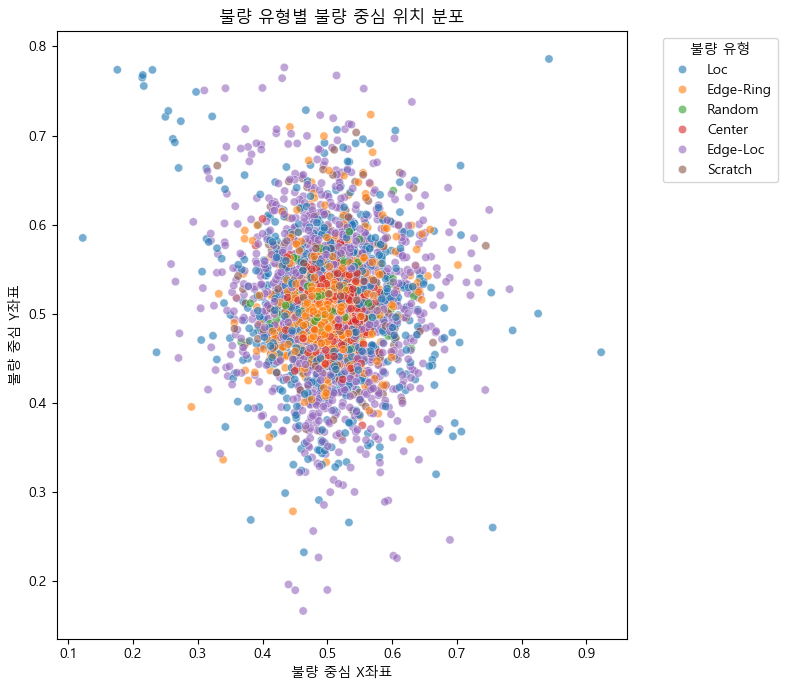

In [33]:
# 시각화용 샘플링
sample_size = min(5000, len(df_features))
df_sample = df_features.sample(sample_size, random_state=42)

plt.figure(figsize=(8, 7))

sns.scatterplot(
    data=df_sample,
    x="defect_center_x",
    y="defect_center_y",
    hue="failureType_clean",
    alpha=0.6
)

plt.title("불량 유형별 불량 중심 위치 분포")
plt.xlabel("불량 중심 X좌표")
plt.ylabel("불량 중심 Y좌표")
plt.legend(title="불량 유형", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.tight_layout()
plt.savefig(os.path.join(fig_dir, "08_불량중심좌표_scatter.png"), dpi=300)
plt.show()

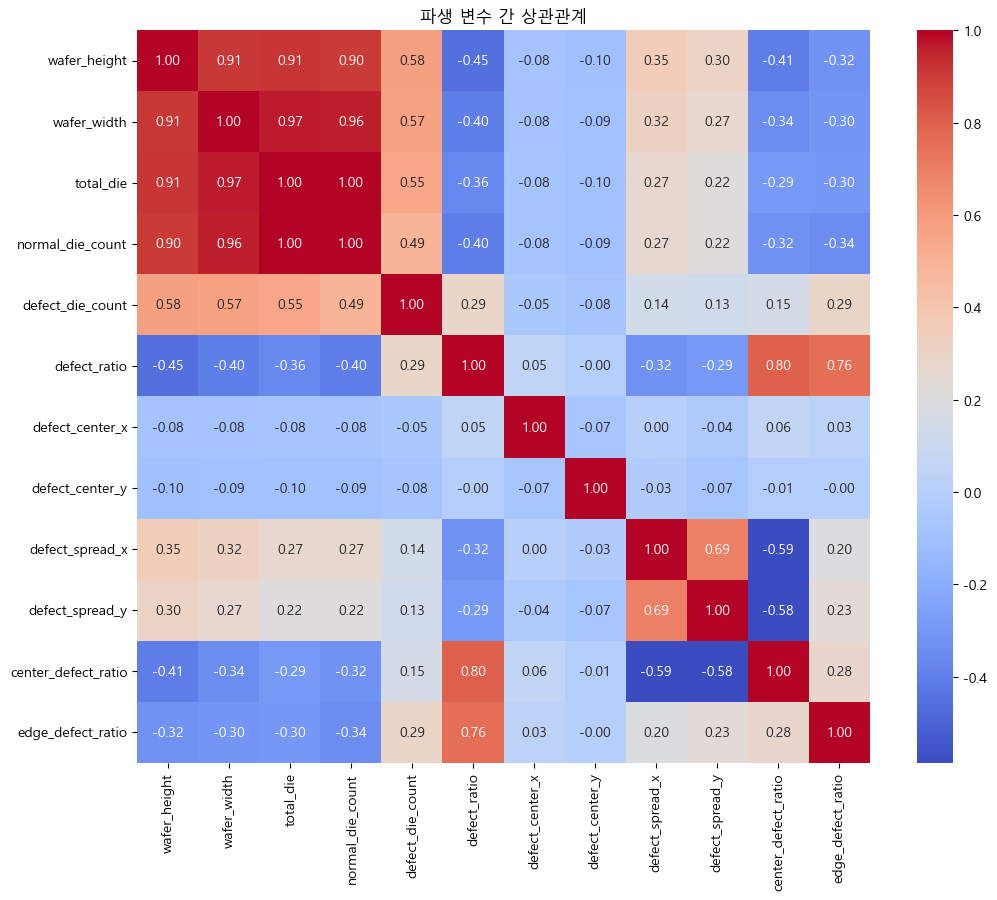

In [34]:
feature_cols = [
    "wafer_height",
    "wafer_width",
    "total_die",
    "normal_die_count",
    "defect_die_count",
    "defect_ratio",
    "defect_center_x",
    "defect_center_y",
    "defect_spread_x",
    "defect_spread_y",
    "center_defect_ratio",
    "edge_defect_ratio"
]

corr = df_features[feature_cols].corr()

plt.figure(figsize=(11, 9))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    square=True
)

plt.title("파생 변수 간 상관관계")
plt.tight_layout()
plt.savefig(os.path.join(fig_dir, "09_파생변수_상관관계_heatmap.png"), dpi=300)
plt.show()

In [35]:
summary_by_class = df_features.groupby("failureType_clean")[feature_cols].mean().round(4)

save_path = r"C:\Users\rosa_\OneDrive\바탕 화면\4학년 1학기\빅데이터분석\project\data\wafer_feature_summary_by_class.xlsx"

summary_by_class.to_excel(save_path)

print("클래스별 파생 변수 요약 저장 완료:", save_path)
display(summary_by_class)

클래스별 파생 변수 요약 저장 완료: C:\Users\rosa_\OneDrive\바탕 화면\4학년 1학기\빅데이터분석\project\data\wafer_feature_summary_by_class.xlsx


,wafer_height,wafer_width,total_die,normal_die_count,defect_die_count,defect_ratio,defect_center_x,defect_center_y,defect_spread_x,defect_spread_y,center_defect_ratio,edge_defect_ratio
failureType_clean,,,,,,,,,,,,
Center,31.9094,33.1323,928.6176,758.1011,170.5165,0.2325,0.5103,0.5020,0.2496,0.2473,0.3635,0.2352
Edge-Loc,38.0222,36.7855,1171.1507,984.0420,187.1087,0.1828,0.5027,0.5091,0.2751,0.2779,0.1198,0.2736
Edge-Ring,52.8403,53.9466,2601.0812,2297.9620,303.1192,0.1513,0.4980,0.5036,0.3163,0.3157,0.0622,0.3002
Loc,39.2906,37.9519,1351.0214,1203.3298,147.6916,0.1500,0.4984,0.5097,0.2528,0.2511,0.1672,0.1625
Random,36.7760,38.1824,1191.2760,641.6744,549.6016,0.4806,0.5004,0.5056,0.2550,0.2577,0.4948,0.5004
Scratch,45.8692,45.3831,2010.4300,1881.0184,129.4116,0.1006,0.5042,0.5133,0.2703,0.2706,0.0862,0.1315


In [36]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [37]:
feature_cols = [
    "wafer_height",
    "wafer_width",
    "total_die",
    "normal_die_count",
    "defect_die_count",
    "defect_ratio",
    "defect_center_x",
    "defect_center_y",
    "defect_spread_x",
    "defect_spread_y",
    "center_defect_ratio",
    "edge_defect_ratio"
]

X = df_features[feature_cols]
y = df_features["failureType_clean"]

print(X.shape)
print(y.value_counts())

(24815, 12)
failureType_clean
Edge-Ring    9680
Edge-Loc     5189
Center       4294
Loc          3593
Scratch      1193
Random        866
Name: count, dtype: int64


In [38]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (19852, 12)
X_test: (4963, 12)
y_train: (19852,)
y_test: (4963,)


In [39]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import pandas as pd
import numpy as np

In [40]:
# Decision Tree
dt_model = DecisionTreeClassifier(
    random_state=42,
    class_weight="balanced",
    max_depth=8
)

dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)

dt_acc = accuracy_score(y_test, dt_pred)

print("Decision Tree Accuracy:", dt_acc)
print(classification_report(y_test, dt_pred))

Decision Tree Accuracy: 0.7169050977231514
              precision    recall  f1-score   support

      Center       0.91      0.64      0.75       859
    Edge-Loc       0.66      0.71      0.69      1038
   Edge-Ring       0.97      0.89      0.93      1936
         Loc       0.58      0.32      0.41       719
      Random       0.74      0.91      0.82       173
     Scratch       0.19      0.70      0.30       238

    accuracy                           0.72      4963
   macro avg       0.68      0.69      0.65      4963
weighted avg       0.79      0.72      0.74      4963



In [41]:
# Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

rf_acc = accuracy_score(y_test, rf_pred)

print("Random Forest Accuracy:", rf_acc)
print(classification_report(y_test, rf_pred))

Random Forest Accuracy: 0.8543219826717711
              precision    recall  f1-score   support

      Center       0.90      0.89      0.89       859
    Edge-Loc       0.76      0.88      0.81      1038
   Edge-Ring       0.98      0.96      0.97      1936
         Loc       0.67      0.66      0.67       719
      Random       0.93      0.92      0.93       173
     Scratch       0.52      0.29      0.37       238

    accuracy                           0.85      4963
   macro avg       0.79      0.77      0.77      4963
weighted avg       0.85      0.85      0.85      4963



In [42]:
model_result = pd.DataFrame({
    "model": ["Decision Tree", "Random Forest"],
    "accuracy": [dt_acc, rf_acc]
})

display(model_result)

save_path = r"C:\Users\rosa_\OneDrive\바탕 화면\4학년 1학기\빅데이터분석\project\data\model_accuracy_result.xlsx"

model_result.to_excel(save_path, index=False)

print("모델 성능 비교 저장 완료:", save_path)

,model,accuracy
0,Decision Tree,0.716905
1,Random Forest,0.854322


모델 성능 비교 저장 완료: C:\Users\rosa_\OneDrive\바탕 화면\4학년 1학기\빅데이터분석\project\data\model_accuracy_result.xlsx


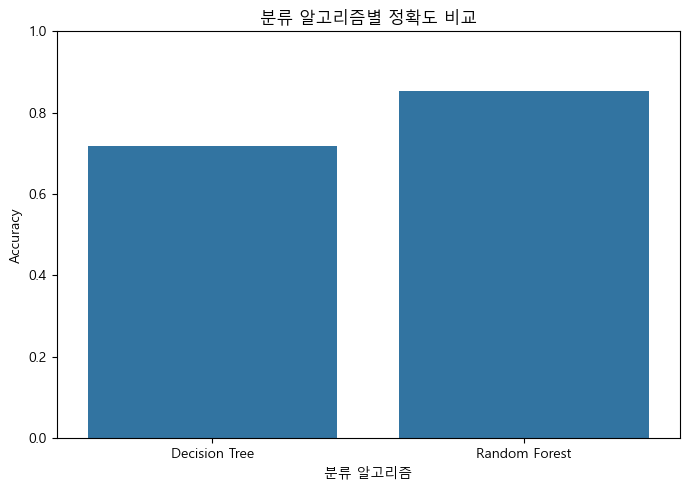

In [43]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=model_result,
    x="model",
    y="accuracy"
)

plt.title("분류 알고리즘별 정확도 비교")
plt.xlabel("분류 알고리즘")
plt.ylabel("Accuracy")
plt.ylim(0, 1)

plt.tight_layout()
plt.savefig(os.path.join(fig_dir, "10_분류알고리즘_정확도_비교.png"), dpi=300)
plt.show()

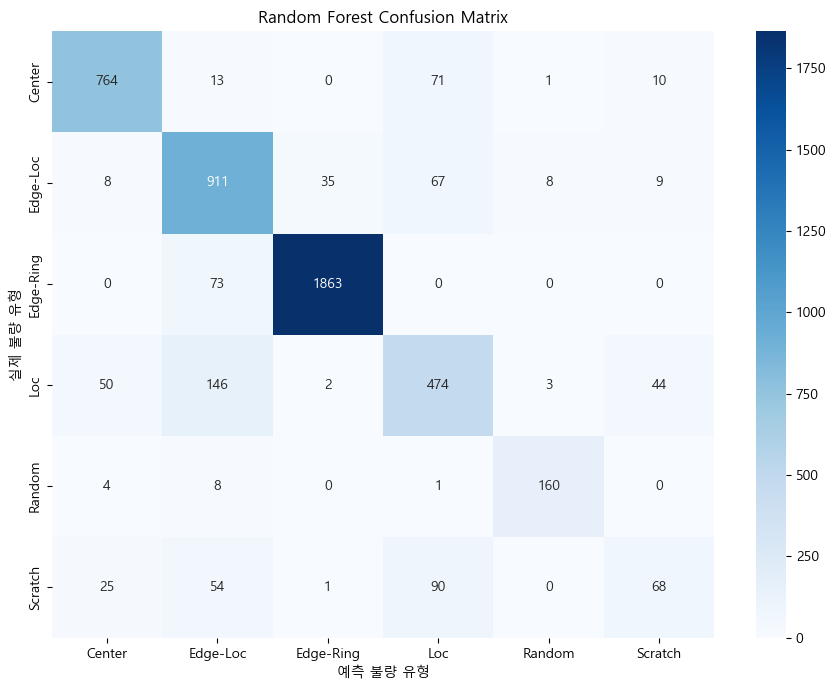

In [44]:
labels = sorted(y_test.unique())

cm = confusion_matrix(y_test, rf_pred, labels=labels)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("예측 불량 유형")
plt.ylabel("실제 불량 유형")

plt.tight_layout()
plt.savefig(os.path.join(fig_dir, "11_random_forest_confusion_matrix.png"), dpi=300)
plt.show()

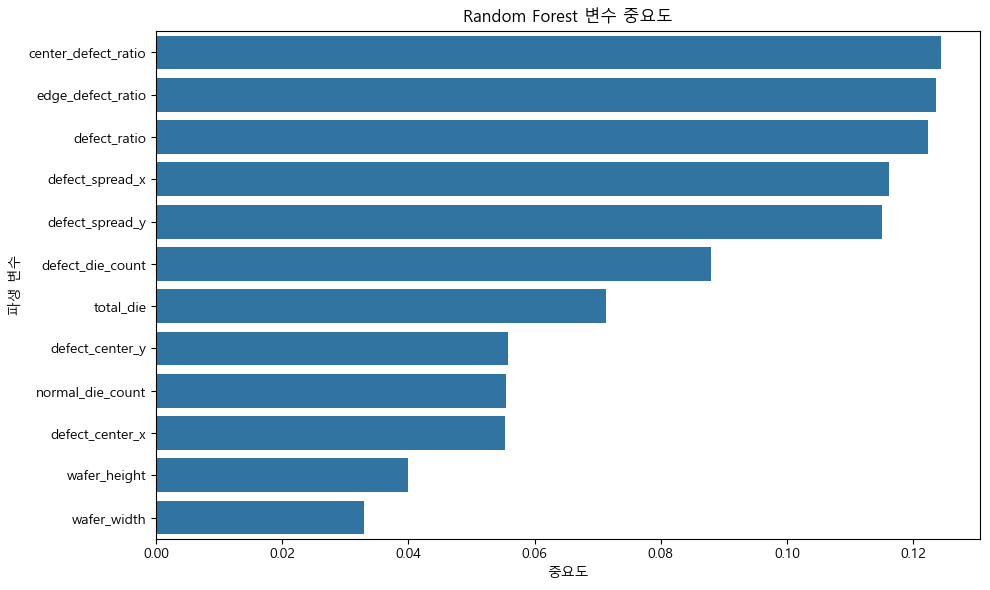

,feature,importance
10,center_defect_ratio,0.124385
11,edge_defect_ratio,0.123617
5,defect_ratio,0.122321
8,defect_spread_x,0.116208
9,defect_spread_y,0.114993
4,defect_die_count,0.087904
2,total_die,0.071348
7,defect_center_y,0.055709
3,normal_die_count,0.055410
6,defect_center_x,0.055260


In [45]:
feature_importance = pd.DataFrame({
    "feature": feature_cols,
    "importance": rf_model.feature_importances_
}).sort_values(by="importance", ascending=False)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="importance",
    y="feature"
)

plt.title("Random Forest 변수 중요도")
plt.xlabel("중요도")
plt.ylabel("파생 변수")

plt.tight_layout()
plt.savefig(os.path.join(fig_dir, "12_random_forest_변수중요도.png"), dpi=300)
plt.show()

display(feature_importance)

In [46]:
save_path = r"C:\Users\rosa_\OneDrive\바탕 화면\4학년 1학기\빅데이터분석\project\data\feature_importance.xlsx"

feature_importance.to_excel(save_path, index=False)

print("변수 중요도 저장 완료:", save_path)

변수 중요도 저장 완료: C:\Users\rosa_\OneDrive\바탕 화면\4학년 1학기\빅데이터분석\project\data\feature_importance.xlsx


In [47]:
from sklearn.metrics import classification_report

# Decision Tree 성능표
dt_report = pd.DataFrame(
    classification_report(y_test, dt_pred, output_dict=True)
).transpose()

# Random Forest 성능표
rf_report = pd.DataFrame(
    classification_report(y_test, rf_pred, output_dict=True)
).transpose()

save_path = r"C:\Users\rosa_\OneDrive\바탕 화면\4학년 1학기\빅데이터분석\project\data\classification_report.xlsx"

with pd.ExcelWriter(save_path, engine="openpyxl") as writer:
    dt_report.to_excel(writer, sheet_name="Decision_Tree")
    rf_report.to_excel(writer, sheet_name="Random_Forest")

print("classification report 저장 완료:", save_path)

classification report 저장 완료: C:\Users\rosa_\OneDrive\바탕 화면\4학년 1학기\빅데이터분석\project\data\classification_report.xlsx
